In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import foxes
import foxes.variables as FV
import foxes.constants as FC

/home/janos/miniforge3/envs/wind/lib/python3.14/site-packages/foxes/core/engine.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
#read in geometry of the N10 wind farms
df_10_1 = pd.read_csv('turbine-info/area_of_interest/layout-N-10.1.geom.csv')
df_10_2 = pd.read_csv('turbine-info/area_of_interest/layout-N-10.2.geom.csv')
print(df_10_1.head())
print(df_10_2.head())

print(len(df_10_1))
print(len(df_10_2))

   Unnamed: 0              x             y
0           0  299005.799984  6.070368e+06
1           1  323948.094387  6.054412e+06
2           2  298349.954443  6.069364e+06
3           3  297371.961785  6.067867e+06
4           4  322931.904806  6.053777e+06
   Unnamed: 0              x             y
0           0  307913.747139  6.055304e+06
1           1  317153.836941  6.050162e+06
2           2  308925.790372  6.055897e+06
3           3  310440.674504  6.056784e+06
4           4  316159.235338  6.049540e+06
133
33


In [3]:
farm = foxes.WindFarm(name="N10")

for turbine in range(len(df_10_1)):
    farm.add_turbine(foxes.Turbine(
        xy=[df_10_1['x'][turbine], df_10_1['y'][turbine]],
        turbine_models=["IEA15MW"]
    ))

for turbine in range(len(df_10_2)):
    farm.add_turbine(foxes.Turbine(
        xy=[df_10_2['x'][turbine], df_10_2['y'][turbine]],
        turbine_models=["IEA15MW"]
    ))


Turbine 0, T0: xy=(299005.80, 6070368.13), IEA15MW
Turbine 1, T1: xy=(323948.09, 6054412.29), IEA15MW
Turbine 2, T2: xy=(298349.95, 6069364.01), IEA15MW
Turbine 3, T3: xy=(297371.96, 6067866.68), IEA15MW
Turbine 4, T4: xy=(322931.90, 6053776.58), IEA15MW
Turbine 5, T5: xy=(298529.18, 6068179.05), IEA15MW
Turbine 6, T6: xy=(299546.60, 6069298.19), IEA15MW
Turbine 7, T7: xy=(322938.13, 6055058.37), IEA15MW
Turbine 8, T8: xy=(321915.72, 6053140.87), IEA15MW
Turbine 9, T9: xy=(298142.83, 6066947.93), IEA15MW
Turbine 10, T10: xy=(320899.53, 6052505.16), IEA15MW
Turbine 11, T11: xy=(321921.94, 6054422.67), IEA15MW
Turbine 12, T12: xy=(299725.82, 6068113.23), IEA15MW
Turbine 13, T13: xy=(300744.40, 6069255.93), IEA15MW
Turbine 14, T14: xy=(319883.34, 6051869.46), IEA15MW
Turbine 15, T15: xy=(299341.24, 6066978.00), IEA15MW
Turbine 16, T16: xy=(321928.16, 6055704.46), IEA15MW
Turbine 17, T17: xy=(320905.75, 6053786.96), IEA15MW
Turbine 18, T18: xy=(318867.15, 6051233.75), IEA15MW
Turbine 19, T

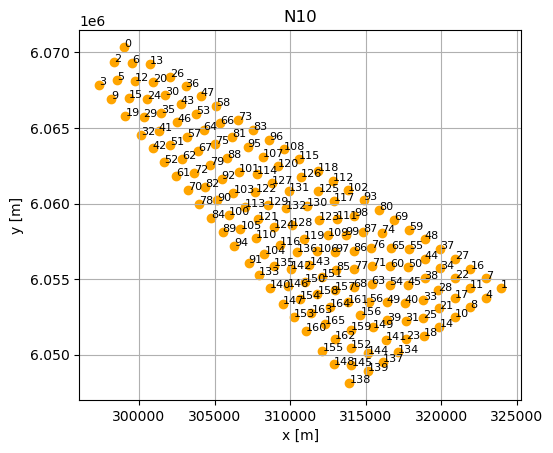

In [4]:
foxes.output.FarmLayoutOutput(farm).get_figure()
plt.show()

In [5]:
states = foxes.input.states.StatesTable(
    data_source="reanalysis/reanalysis_2006.csv",
    output_vars=[FV.WS, FV.WD, FV.TI, FV.RHO],
    var2col={FV.WS: "WS100", FV.WD: "WD100"},
    fixed_vars={FV.RHO: 1.225, FV.TI: 0.05},
)

In [6]:
mbook = foxes.ModelBook()

In [7]:
algo = foxes.algorithms.Downwind(
    mbook=mbook,
    farm=farm,
    states=states,
    rotor_model="centre",
    wake_models=["Bastankhah2014_linear_k004"],
    wake_frame="rotor_wd",
    partial_wakes=None,
)

In [8]:
engine = foxes.Engine.new(
    engine_type="process",
    n_procs=4,
    chunk_size_states=1000,
    chunk_size_points=3000,
)
print(engine)

ProcessEngine(n_procs=4, chunk_size_states=1000, chunk_size_points=3000)


ProcessEngine: Calculating 8760 states for 1 turbines
ProcessEngine: Starting calculation using 3 workers, for 9 states chunks.


  0%|          | 0/9 [00:00<?, ?it/s]

ProcessEngine: Completed all 9 chunks



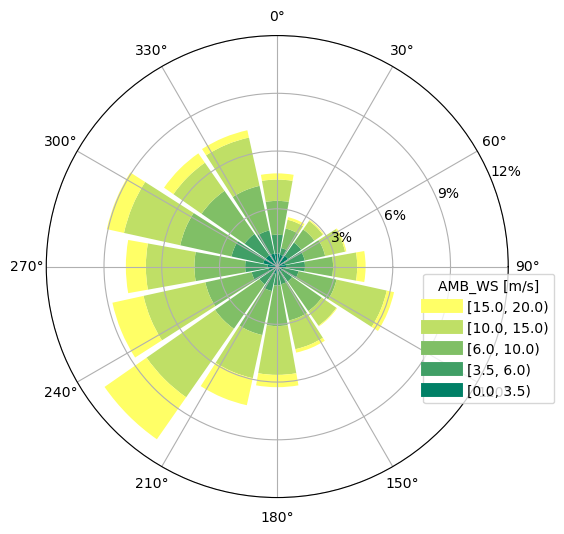

In [9]:
with engine:
    o = foxes.output.StatesRosePlotOutput(states, point=[0., 0., 100.])
    fig = o.get_figure(16, FV.AMB_WS, [0, 3.5, 6, 10, 15, 20], figsize=(6, 6))
plt.show()

In [10]:
with engine:
    farm_results = algo.calc_farm()

Initializing model 'StatesTable'
States 'StatesTable': Reading file reanalysis/reanalysis_2006.csv

Initializing algorithm 'Downwind'

------------------------------------------------------------
  Algorithm: Downwind
  Running Downwind: calc_farm
------------------------------------------------------------
  n_states : 8760
  n_turbines: 166
------------------------------------------------------------
  states    : StatesTable()
  rotor     : CentreRotor()
  controller: BasicFarmController()
  deflection: NoDeflection()
  wake frame: RotorWD()
  wake lngth: None
------------------------------------------------------------
  wakes:
    0) Bastankhah2014_linear_k004: Bastankhah2014(ws_linear, induction=Madsen, k=0.04)
------------------------------------------------------------
  partial wakes:
    0) Bastankhah2014_linear_k004: axiwake6, PartialAxiwake(n=6)
------------------------------------------------------------
  turbine models:
    0) IEA15MW: PCtFile(D=240.0, H=150.0, P_nominal

  0%|          | 0/9 [00:00<?, ?it/s]

ProcessEngine: Completed all 9 chunks





In [11]:
farm_results

<xarray.Dataset> Size: 291MB
Dimensions:     (state: 8760, turbine: 166)
Coordinates:
  * state       (state) object 70kB '2006-01-01 00:00:00' ... '2006-12-31 23:...
Dimensions without coordinates: turbine
Data variables: (12/27)
    AMB_CT      (state, turbine) float64 12MB 0.8045 0.8045 ... 0.06879 0.06879
    AMB_P       (state, turbine) float64 12MB 7.896e+03 7.896e+03 ... 1.5e+04
    AMB_REWS    (state, turbine) float64 12MB 8.515 8.515 8.515 ... 21.69 21.69
    AMB_REWS2   (state, turbine) float64 12MB 8.515 8.515 8.515 ... 21.69 21.69
    AMB_REWS3   (state, turbine) float64 12MB 8.515 8.515 8.515 ... 21.69 21.69
    AMB_RHO     (state, turbine) float64 12MB 1.225 1.225 1.225 ... 1.225 1.225
    ...          ...
    YAW         (state, turbine) float64 12MB 243.1 243.1 243.1 ... 239.0 239.0
    order       (state, turbine) int64 12MB 3 9 19 32 5 42 15 ... 11 27 4 16 7 1
    order_inv   (state, turbine) int64 12MB 135 69 159 18 62 ... 19 128 112 8
    order_ssel  (state, turbine) int64 12MB 0 0 0 0 0 0 ... 973 973 973 973 973
    weight      (state) float64 70kB 0.0001142 0.0001142 ... 0.0001142 0.0001142
    tname       (turbine) <U4 3kB 'T0' 'T1' 'T2' 'T3' ... 'T163' 'T164' 'T165'

In [12]:
farm_results["P"]

<xarray.DataArray 'P' (state: 8760, turbine: 166)> Size: 12MB
array([[ 7896.21162749,  3216.85479317,  7896.21999927, ...,
         7287.95884696,  6434.82247382,  6212.43058603],
       [ 7522.49164361,  4095.54120988,  7522.492     , ...,
         6113.03019183,  4936.97620169,  4824.25238864],
       [ 5992.6235065 ,  3108.54505493,  5992.62399999, ...,
         5056.80112407,  4117.29040471,  3995.52748576],
       ...,
       [14996.2844816 , 14996.4456    , 14996.38063824, ...,
        14996.36628667, 14996.40325705, 14996.44559829],
       [14997.16343327, 14997.34833537, 14997.26794845, ...,
        14997.34873352, 14997.31333085, 14997.3488    ],
       [14995.67559926, 14995.24072976, 14995.6756    , ...,
        14995.67409119, 14995.66855218, 14995.66573329]],
      shape=(8760, 166))
Coordinates:
  * state    (state) object 70kB '2006-01-01 00:00:00' ... '2006-12-31 23:00:00'
Dimensions without coordinates: turbine

In [13]:
P = farm_results["P"].values
print(P)
print("Numpy shape:", P.shape)

[[ 7896.21162749  3216.85479317  7896.21999927 ...  7287.95884696
   6434.82247382  6212.43058603]
 [ 7522.49164361  4095.54120988  7522.492      ...  6113.03019183
   4936.97620169  4824.25238864]
 [ 5992.6235065   3108.54505493  5992.62399999 ...  5056.80112407
   4117.29040471  3995.52748576]
 ...
 [14996.2844816  14996.4456     14996.38063824 ... 14996.36628667
  14996.40325705 14996.44559829]
 [14997.16343327 14997.34833537 14997.26794845 ... 14997.34873352
  14997.31333085 14997.3488    ]
 [14995.67559926 14995.24072976 14995.6756     ... 14995.67409119
  14995.66855218 14995.66573329]]
Numpy shape: (8760, 166)


In [14]:
o = foxes.output.FarmResultsEval(farm_results)
turbine_results = o.reduce_states({FV.REWS: "weights", FV.P: "weights"})
turbine_results

,REWS,P
turbine,,
0,9.363913,8535.869674
1,9.168512,8293.185263
2,9.345045,8500.578137
3,9.424645,8634.105670
4,9.056408,8101.053657
...,...,...
161,8.822357,7676.053667
162,8.987824,7921.518219
163,8.972762,7878.297415


In [15]:
P0_mean = o.calc_mean_farm_power(ambient=True)
P_mean = o.calc_mean_farm_power()
print(f"\nFarm power        : {P_mean/1000:.1f} MW")
print(f"Farm ambient power: {P0_mean/1000:.1f} MW")
print(f"Farm efficiency   : {o.calc_farm_efficiency()*100:.2f} %")
print(f"Annual farm yield : {o.calc_farm_yield(algo=algo):.2f} GWh")


Farm power        : 1300.7 MW
Farm ambient power: 1514.9 MW
Farm efficiency   : 85.86 %
Annual farm yield : 11394.26 GWh


States 'StatesTable': Reading file reanalysis/reanalysis_2006.csv
ProcessEngine: Calculating data at 1880 points for 8760 states
ProcessEngine: Starting calculation using 3 workers, for 9 states chunks.


  0%|          | 0/9 [00:00<?, ?it/s]

ProcessEngine: Completed all 9 chunks



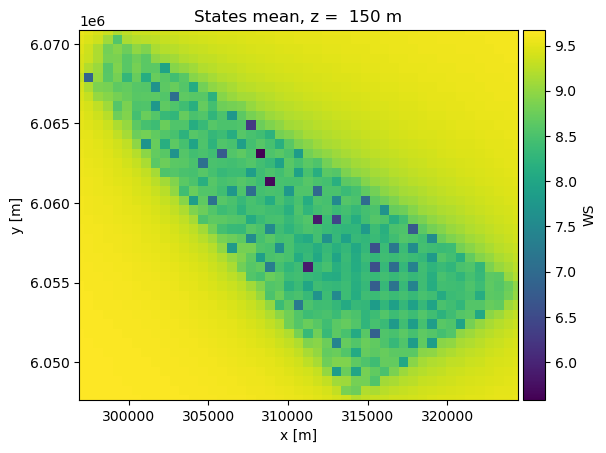

In [16]:
with engine:
    o = foxes.output.FlowPlots2D(algo, farm_results)
    plot_data = o.get_mean_data_xy(FV.WS, resolution=600)

# create the flow figure, not in parallel since the underlying plt does not like that:
o.get_mean_fig_xy(plot_data)
plt.show()